# metallic MAX 相

## 問題意識

LSI（CPU/GPU 等）の電力消費は大きく
1. CMOS の充放電電力（∝$C V^2 $)
2. 配線の抵抗と配線がコンデンサとなることに起因する電力・遅延
の2つの視点で捉えられる。

微細化が進むほどトランジスタは高速化する一方、
配線は細くなり抵抗が急増し、電力への寄与が大きくなる。
現在の先端プロセスでは、トランジスタ電力と配線電力の比重がほぼ同程度である。

## 問題解決法

1. 配線長を短くする：物理設計・アーキテクチャの領域
2. 配線抵抗 R を下げる：材料科学の領域

であり、後者の材料探索が行われている。

## MAX相とは？

組成式$M_{n+1} A X_{n}$の組成式を持つ。
- M: early transition metal
- A: カラム13 or 14の元素
- X: C or N

とても硬い、かつ電気伝導度が高いことで知られている。

## MAX 相の結晶構造

n=2,3,4,... が知られている。n>=3では同じ組成式でalpha構造とbeta構造がある。

- n=3, alpha相

![](image_keep/alpha-C6Cd2Ti8.png)

- n=3, beta 相

![](image_keep/beta-C6Cd2Ti8.png)


参考文献の表II、III,IVに
- 組成、alpha,beta構造の別と

- $\Delta Hf$: formationenthalpy
- $\Delta H_{coh}$: cohesive energy, 
- $\rho_0 \times \lambda_{\perp, \tau}$: bulk resistivity $\times$ mean free path, no $k$-dependence relaxation time approximation 
- $\rho_0 \times \lambda_{\perp, \lambda}$: bulk resistivity $\times$ mean free path, no $k$-dependent mean free path approximation

が出力されている。$\rho_0 \times \lambda$は線幅が小さくなったときの抵抗増加のしにくさの指標であり、これは小さい方が良い。

参考文献：
Kiroubanand Sankaran , Kristof Moors
 , Zsolt T˝okei,1 Christoph Adelmann
 , and Geoffrey Pourtois, " Ab initio screening of metallic MAX ceramics for advanced interconnect applications", 
 PHYSICAL REVIEW MATERIALS 5,056002(2021), 
DOI: 10.1103/PhysRevMaterials.5.056002

## 特徴量

- n=>3に対してはalpha, betaに対してdummy変数(adirection, bdirection）を加えている。

- 説明変数として、構成元素M, A, Xの特徴量、組成式としての特徴量(組成比で最大、最小、平均、標準偏差）を加えている。

In [1]:
import pandas as pd

def get_data(delete_exceptional=True):
    
    df_data =  pd.read_csv("../data/maxphase_property.csv")
    
    target_features = ["Hf (eV/atom)","Ecoh (eV/atom)", "(ρ0 × λ)⊥τ (10^-16 m2)",
     "(ρ0 × λ)⊥λ (10^-16 m2)"]
    
    descriptors = ['n','adirection',
        'bdirection', 'TM_Z', 'TM_row', 'TM_group',
        'TM_atomic_radius_calculated', 'TM_mendeleev_no',
        'TM_electrical_resistivity', 'TM_poissons_ratio', 'TM_molar_volume',
        'TM_thermal_conductivity', 'TM_boiling_point', 'TM_melting_point',
        'TM_liquid_range', 'TM_bulk_modulus', 'TM_youngs_modulus',
        'TM_brinell_hardness', 'TM_rigidity_modulus', 'TM_mineral_hardness',
        'TM_vickers_hardness', 'TM_density_of_solid',
        'TM_coefficient_of_linear_thermal_expansion', 'TM_ionization_energies',
        'TM_atomic_mass', 'TM_atomic_radius', 'TM_average_anionic_radius',
        'TM_average_cationic_radius', 'TM_average_ionic_radius',
        'TM_electron_affinity', 'A_Z', 'A_row', 'A_group',
        'A_atomic_radius_calculated', 'A_mendeleev_no',
        'A_electrical_resistivity', 'A_molar_volume', 'A_thermal_conductivity',
        'A_boiling_point', 'A_melting_point', 'A_liquid_range',
        'A_mineral_hardness', 'A_density_of_solid', 'A_ionization_energies',
        'A_atomic_mass', 'A_atomic_radius', 'A_average_anionic_radius',
        'A_average_cationic_radius', 'A_average_ionic_radius',
        'A_electron_affinity', 'X_Z', 'X_row', 'X_group',
        'X_atomic_radius_calculated', 'X_mendeleev_no', 'X_refractive_index',
        'X_molar_volume', 'X_thermal_conductivity', 'X_boiling_point',
        'X_melting_point', 'X_liquid_range', 'X_ionization_energies',
        'X_atomic_mass', 'X_atomic_radius', 'X_average_anionic_radius',
        'X_average_cationic_radius', 'X_average_ionic_radius',
        'X_electron_affinity',
        'mean_Z',
        'stddev_Z',
        'mean_row',
        'stddev_row',
        'mean_group',
        'stddev_group',
        'mean_atomic_radius_calculated',
        'stddev_atomic_radius_calculated',
        'mean_mendeleev_no',
        'stddev_mendeleev_no',
        'mean_molar_volume',
        'stddev_molar_volume',
        'mean_thermal_conductivity',
        'stddev_thermal_conductivity',
        'mean_boiling_point',
        'stddev_boiling_point',
        'mean_melting_point',
        'stddev_melting_point',
        'mean_liquid_range',
        'stddev_liquid_range',
        'mean_ionization_energies',
        'stddev_ionization_energies',
        'mean_atomic_mass',
        'stddev_atomic_mass',
        'mean_atomic_radius',
        'stddev_atomic_radius',
        'mean_average_anionic_radius',
        'stddev_average_anionic_radius',
        'mean_average_cationic_radius',
        'stddev_average_cationic_radius',
        'mean_average_ionic_radius',
        'stddev_average_ionic_radius',
        'mean_electron_affinity',
        'stddev_electron_affinity']

    if delete_exceptional:
        df_data = df_data[df_data[target_features[2]]<100]

    return df_data, descriptors, target_features

g_df_data, g_feat_cols, g_target_cols  = get_data(delete_exceptional=False)

In [2]:
g_df_data

,Material,Hf (eV/atom),Ecoh (eV/atom),(ρ0 × λ)⊥τ (10^-16 m2),(ρ0 × λ)⊥λ (10^-16 m2),n,adirection,bdirection,TM_Z,TM_row,...,mean_atomic_radius,stddev_atomic_radius,mean_average_anionic_radius,stddev_average_anionic_radius,mean_average_cationic_radius,stddev_average_cationic_radius,mean_average_ionic_radius,stddev_average_ionic_radius,mean_electron_affinity,stddev_electron_affinity
0,Ti2AlC,-3.110,7.3,7.5,7.6,2,0,0,22.0,4.0,...,1.18750,0.288043,0.000,0.000000,0.669583,0.225239,0.669583,0.225239,0.461510,0.484697
1,Ti2AlN,-3.148,5.4,7.6,6.5,2,0,0,22.0,4.0,...,1.17500,0.309233,0.330,0.571577,0.665833,0.231401,0.752083,0.100846,0.128481,0.185493
2,Ti2SiC,-0.805,7.8,6.0,6.1,2,0,0,22.0,4.0,...,1.15000,0.287228,0.000,0.000000,0.635833,0.231914,0.635833,0.231914,0.700681,0.626757
3,Ti2GaN,-0.823,5.2,10.1,10.6,2,0,0,22.0,4.0,...,1.18750,0.313000,0.330,0.571577,0.687083,0.235140,0.773333,0.090822,0.095573,0.132759
4,Ti2GeC,-0.687,7.6,6.1,6.1,2,0,0,22.0,4.0,...,1.18750,0.288043,0.000,0.000000,0.693333,0.229525,0.693333,0.229525,0.661470,0.586017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,α-Cr4AlC3,-0.010,6.9,1.0,1.1,4,1,0,24.0,4.0,...,1.11875,0.327812,0.000,0.000000,0.666875,0.296278,0.666875,0.296278,0.865318,0.316818
103,β-Cr4SiN3,-2.672,3.5,2.9,4.3,4,0,1,24.0,4.0,...,1.08125,0.347255,0.495,0.639042,0.644375,0.305762,0.773750,0.168518,0.485361,0.485787
104,α-Cr4GeN3,-3.125,3.8,1.5,1.4,4,1,0,24.0,4.0,...,1.10000,0.351781,0.495,0.639042,0.673125,0.305409,0.802500,0.144027,0.465755,0.450807
105,α-Ta4AlC3,-0.582,9.4,3.8,3.3,4,1,0,73.0,6.0,...,1.14375,0.349497,0.000,0.000000,0.606875,0.242086,0.606875,0.242086,0.688957,0.445319


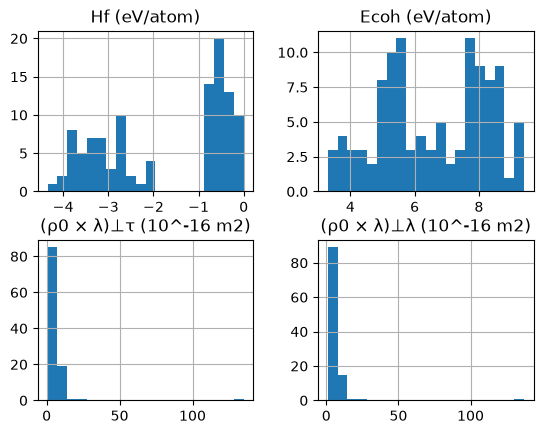

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,2)
for i in range(2):
    for j in range(2):
        g_df_data.hist(g_target_cols[i*2+j], ax=axes[i,j], bins=20)


'(ρ0 × λ)'には'特に大きな値'がある。

array([[<Axes: title={'center': '(ρ0 × λ)⊥τ (10^-16 m2)'}>]], dtype=object)

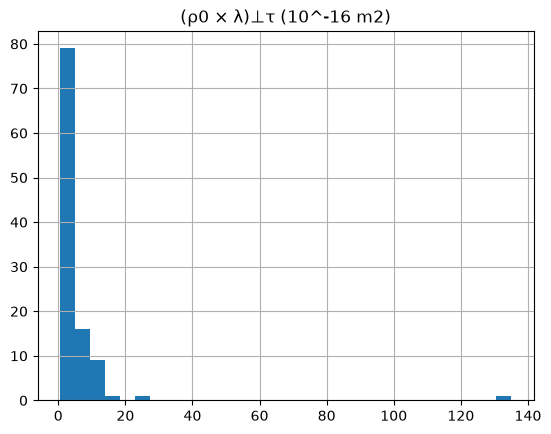

In [4]:
g_df_data.hist(g_target_cols[2], bins=30)

array([[<Axes: title={'center': '(ρ0 × λ)⊥λ (10^-16 m2)'}>]], dtype=object)

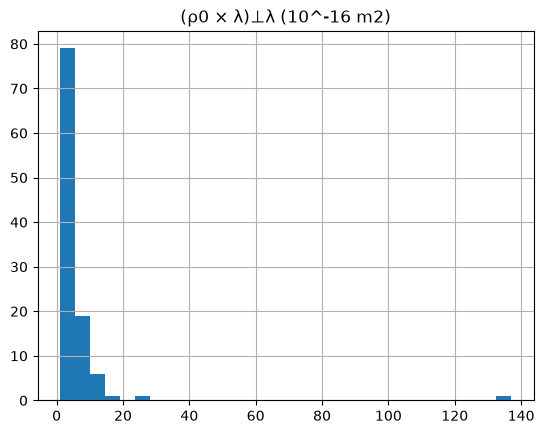

In [5]:
g_df_data.hist(g_target_cols[3], bins=30)

In [6]:
g_df_data = g_df_data[g_df_data[g_target_cols[2]]<100].reset_index(drop=True)


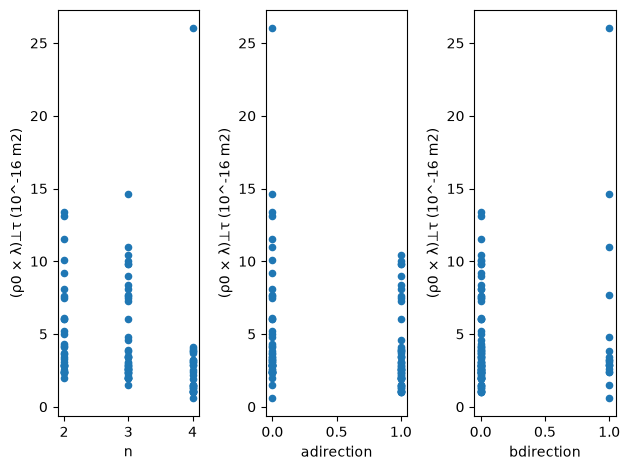

In [7]:
fig, axes  = plt.subplots(1,3)
g_df_data.plot.scatter('n',g_target_cols[2], ax=axes[0])
g_df_data.plot.scatter('adirection',g_target_cols[2], ax=axes[1])
g_df_data.plot.scatter('bdirection',g_target_cols[2], ax=axes[2])
plt.tight_layout()

In [8]:
g_df_data.columns

Index(['Material', 'Hf (eV/atom)', 'Ecoh (eV/atom)', '(ρ0 × λ)⊥τ (10^-16 m2)',
       '(ρ0 × λ)⊥λ (10^-16 m2)', 'n', 'adirection', 'bdirection', 'TM_Z',
       'TM_row',
       ...
       'mean_atomic_radius', 'stddev_atomic_radius',
       'mean_average_anionic_radius', 'stddev_average_anionic_radius',
       'mean_average_cationic_radius', 'stddev_average_cationic_radius',
       'mean_average_ionic_radius', 'stddev_average_ionic_radius',
       'mean_electron_affinity', 'stddev_electron_affinity'],
      dtype='object', length=107)

In [9]:
# ① 先頭に付いている α- / β- だけを消したい場合
g_df_data['formula'] = g_df_data['Material'].str.replace(r'^[αβ]-', '', regex=True)


In [10]:
g_df_data['formula']

0       Ti2AlC
1       Ti2AlN
2       Ti2SiC
3       Ti2GaN
4       Ti2GeC
        ...   
101    Cr4AlC3
102    Cr4SiN3
103    Cr4GeN3
104    Ta4AlC3
105    Ta4SiC3
Name: formula, Length: 106, dtype: object

In [11]:
# 同じformulaでα-,β-が含まれる場合は？
for mat, df_mat in g_df_data.groupby('formula'):
    if df_mat.shape[0]>1:
        print('Material =', mat, df_mat.shape[0])


Material = Ta3AlN2 2
Material = Ta3SiC2 2
Material = Ti3GaN2 2
Material = Ti3GeN2 2
Material = Ti3InN2 2
Material = Ti3SiC2 2
Material = Ti3SnC2 2
Material = Ti4GaC3 2
Material = Ti4GeN3 2
Material = Ti4SiC3 2
Material = V3AlC2 2
Material = V4AlC3 2
Material = V4AlN3 2
